# Topic declaration: phosphorus in the Cahaba River

**Question:** Does the water quality in the Cahaba River exceed the median limit of 35 µg/L total phosphorus, and how has the quality changed since the limit was set in September 2006?

**Data:** Water Quality Portal (National Water Quality Monitoring Council: USGS, EPA and the Alabama Department of Environmental Management), every phosphorus result for the Cahaba River watershed, hydrologic unit 03150202. Query URL: <https://www.waterqualitydata.us/data/Result/search?huc=03150202&characteristicName=Phosphorus&characteristicName=Total%20Phosphorus%2C%20mixed%20forms&mimeType=csv&zip=no>, accessed 2026-11-08. Saved unchanged as `data/wqp_cahaba_phosphorus.csv`, SHA-256 `85d57afa86b8c613b5ed03bfca60c5da2b411780dc065ffe8fcd5e25e83bfa97`. One row is one phosphorus result for one sample.

The next cell reads the file with every column as text, so that site identifiers such as `21AWIC-445` and the unit codes stay exactly as written. It prints the number of rows, the 63 column names, and the units recorded for the measured variable, `ResultMeasureValue`. The file mixes several unit codes, mostly mg/L and mg/l as P, so all of them are counted rather than one assumed.

In [1]:
import pandas as pd

data = pd.read_csv("data/wqp_cahaba_phosphorus.csv", dtype=str)
print(f"{len(data)} rows")
print(list(data.columns))
print("phosphorus, ResultMeasureValue, in the units of ResultMeasure/MeasureUnitCode:")
print(data["ResultMeasure/MeasureUnitCode"].value_counts(dropna=False).to_string())

4699 rows
['OrganizationIdentifier', 'OrganizationFormalName', 'ActivityIdentifier', 'ActivityTypeCode', 'ActivityMediaName', 'ActivityMediaSubdivisionName', 'ActivityStartDate', 'ActivityStartTime/Time', 'ActivityStartTime/TimeZoneCode', 'ActivityEndDate', 'ActivityEndTime/Time', 'ActivityEndTime/TimeZoneCode', 'ActivityDepthHeightMeasure/MeasureValue', 'ActivityDepthHeightMeasure/MeasureUnitCode', 'ActivityDepthAltitudeReferencePointText', 'ActivityTopDepthHeightMeasure/MeasureValue', 'ActivityTopDepthHeightMeasure/MeasureUnitCode', 'ActivityBottomDepthHeightMeasure/MeasureValue', 'ActivityBottomDepthHeightMeasure/MeasureUnitCode', 'ProjectIdentifier', 'ActivityConductingOrganizationText', 'MonitoringLocationIdentifier', 'ActivityCommentText', 'SampleAquifer', 'HydrologicCondition', 'HydrologicEvent', 'SampleCollectionMethod/MethodIdentifier', 'SampleCollectionMethod/MethodIdentifierContext', 'SampleCollectionMethod/MethodName', 'SampleCollectionEquipmentName', 'ResultDetectionCondit

## 0.1. Parameters

These values define the numerical and temporal choices used in the analysis. The growing season is defined by the student as April 1 through October 31, inclusive.

In [2]:
LIMIT_MG_P_L = 0.035  # mg/L as P; 35 µg/L phosphorus target
LIMIT_CUTOFF_DATE = "2006-09-01"  # start of the post-limit period
GROWING_SEASON_START_MONTH = 4  # month number; April
GROWING_SEASON_START_DAY = 1  # day of month; inclusive start
GROWING_SEASON_END_MONTH = 10  # month number; October
GROWING_SEASON_END_DAY = 31  # day of month; inclusive end
OUTLIER_IQR_MULTIPLIER = 1.5  # IQR multiplier; standard exploratory outlier-screening rule

## 1.1. First cleaned table

This cell creates a table of growing-season total-phosphorus results for the five stations with the most ADEM measurements. It converts micrograms per liter to milligrams per liter and retains results in phosphorus units. Non-detected and missing-value rows are shown as exclusions for now rather than given a substituted concentration.

In [3]:
ADEM_STATION_IDS = [
    "21AWIC-445",
    "21AWIC-443",
    "21AWIC-347",
    "21AWIC-672",
    "21AWIC-452",
]  # station identifiers; five largest ADEM station counts

measurement_units = data["ResultMeasure/MeasureUnitCode"]
phosphorus_mg_p_l = pd.to_numeric(data["ResultMeasureValue"], errors="coerce")
is_ug_per_l = measurement_units.str.strip().str.lower() == "ug/l"
phosphorus_mg_p_l = phosphorus_mg_p_l.mask(is_ug_per_l, phosphorus_mg_p_l / 1000)

clean_table = data.assign(
    sample_date=pd.to_datetime(data["ActivityStartDate"], errors="coerce"),
    phosphorus_mg_p_l=phosphorus_mg_p_l,
)

is_adem = clean_table["OrganizationFormalName"].str.contains("ALABAMA DEPT", na=False)
is_adem_station = clean_table["MonitoringLocationIdentifier"].isin(ADEM_STATION_IDS)
is_total = (
    clean_table["ResultSampleFractionText"].eq("Total")
    | clean_table["CharacteristicName"].eq("Total Phosphorus, mixed forms")
)
allowed_units = ["mg/L", "mg/l", "mg/l as P", "ug/L"]
is_allowed_unit = measurement_units.isin(allowed_units)

clean_table = clean_table.loc[
    is_adem
    & is_adem_station
    & is_total
    & is_allowed_unit
    & clean_table["ActivityMediaName"].eq("Water")
].copy()

clean_table["growing_season"] = (
    clean_table["sample_date"].dt.month.gt(GROWING_SEASON_START_MONTH - 1)
    & clean_table["sample_date"].dt.month.lt(GROWING_SEASON_END_MONTH + 1)
    & clean_table["sample_date"].notna()
)
clean_table = clean_table.loc[
    clean_table["growing_season"]
    & clean_table["phosphorus_mg_p_l"].notna()
].copy()

cutoff_date = pd.Timestamp(LIMIT_CUTOFF_DATE)
clean_table["period"] = pd.cut(
    clean_table["sample_date"],
    bins=[pd.Timestamp.min, cutoff_date, pd.Timestamp.max],
    labels=["Before September 2006", "After September 2006"],
    include_lowest=True,
)

growing_season_summary = (
    clean_table.groupby(["MonitoringLocationIdentifier", "period"], observed=True)
    .agg(
        sample_count=("phosphorus_mg_p_l", "count"),
        median_mg_p_l=("phosphorus_mg_p_l", "median"),
    )
    .reset_index()
)
growing_season_summary["median_ug_p_l"] = (
    growing_season_summary["median_mg_p_l"] * 1000
).round(1)
growing_season_summary["exceeds_limit"] = (
    growing_season_summary["median_mg_p_l"] > LIMIT_MG_P_L
)

growing_season_summary

,MonitoringLocationIdentifier,period,sample_count,median_mg_p_l,median_ug_p_l,exceeds_limit
0,21AWIC-347,Before September 2006,1,0.252,252.0,True
1,21AWIC-347,After September 2006,75,0.031,31.0,False
2,21AWIC-443,Before September 2006,1,0.031,31.0,False
3,21AWIC-443,After September 2006,103,0.024,24.0,False
4,21AWIC-445,After September 2006,101,0.026,26.0,False
5,21AWIC-452,Before September 2006,1,0.207,207.0,True
6,21AWIC-452,After September 2006,93,0.029,29.0,False
7,21AWIC-672,After September 2006,78,0.110,110.0,True


The table above is an early result. Check the displayed medians against the raw plots and units before interpreting them scientifically: a median above 0.035 mg/L exceeds the 35 µg/L limit, but field replicates and non-detected values have not yet been resolved.

## 1.2. Audit of older sample records

This cell examines ADEM water records at the five selected stations before September 2006 during April–October, without requiring a total-fraction label or a recognized unit. The counts and example rows help identify metadata that needs checking; they do not decide whether a result is valid.

The 343 older growing-season records with no sample-fraction label cannot be confirmed as total phosphorus, so these results are a legacy-phosphorus sensitivity analysis rather than a definitive total-phosphorus median. The remaining 3 records explicitly labeled "Total" should be interpreted separately.

In [4]:
audit_data = data.assign(
    sample_date=pd.to_datetime(data["ActivityStartDate"], errors="coerce")
)
is_audit_record = (
    audit_data["OrganizationFormalName"].str.contains("ALABAMA DEPT", na=False)
    & audit_data["MonitoringLocationIdentifier"].isin(ADEM_STATION_IDS)
    & audit_data["ActivityMediaName"].eq("Water")
    & audit_data["sample_date"].lt(pd.Timestamp(LIMIT_CUTOFF_DATE))
    & audit_data["sample_date"].dt.month.between(
        GROWING_SEASON_START_MONTH, GROWING_SEASON_END_MONTH
    )
)
older_sample_audit = audit_data.loc[is_audit_record].copy()

print(f"Older growing-season ADEM records at the selected stations: {len(older_sample_audit)}")
print(
    "Date range:",
    older_sample_audit["sample_date"].min(),
    "to",
    older_sample_audit["sample_date"].max(),
)

audit_columns = [
    "ResultSampleFractionText",
    "ResultMeasure/MeasureUnitCode",
    "ResultDetectionConditionText",
    "MeasureQualifierCode",
    "ResultStatusIdentifier",
    "DetectionQuantitationLimitTypeName",
    "DetectionQuantitationLimitMeasure/MeasureUnitCode",
]
for column in audit_columns:
    print(f"\n{column}:")
    print(
        older_sample_audit[column]
        .fillna("(missing)")
        .replace("", "(blank)")
        .value_counts(dropna=False)
        .to_string()
    )

example_columns = [
    "ActivityStartDate",
    "MonitoringLocationIdentifier",
    "ResultSampleFractionText",
    "ResultMeasureValue",
    "ResultMeasure/MeasureUnitCode",
    "ResultDetectionConditionText",
    "MeasureQualifierCode",
    "ResultStatusIdentifier",
    "DetectionQuantitationLimitMeasure/MeasureValue",
    "DetectionQuantitationLimitMeasure/MeasureUnitCode",
]
missing_fraction = older_sample_audit["ResultSampleFractionText"].isna() | older_sample_audit[
    "ResultSampleFractionText"
].eq("")
print("\nExample older records with a missing fraction label (up to 20):")
print(
    older_sample_audit.loc[missing_fraction, example_columns]
    .head(20)
    .to_string(index=False)
)

Older growing-season ADEM records at the selected stations: 346
Date range: 1991-04-23 00:00:00 to 2006-08-24 00:00:00

ResultSampleFractionText:
ResultSampleFractionText
(missing)    343
Total          3

ResultMeasure/MeasureUnitCode:
ResultMeasure/MeasureUnitCode
mg/L         306
(missing)     40

ResultDetectionConditionText:
ResultDetectionConditionText
(missing)       306
Not Detected     40

MeasureQualifierCode:
MeasureQualifierCode
(missing)    346

ResultStatusIdentifier:
ResultStatusIdentifier
Final    346

DetectionQuantitationLimitTypeName:
DetectionQuantitationLimitTypeName
(missing)                 306
Method Detection Level     40

DetectionQuantitationLimitMeasure/MeasureUnitCode:
DetectionQuantitationLimitMeasure/MeasureUnitCode
(missing)    306
mg/L          40

Example older records with a missing fraction label (up to 20):
ActivityStartDate MonitoringLocationIdentifier ResultSampleFractionText ResultMeasureValue ResultMeasure/MeasureUnitCode ResultDetectionConditio

## 1.3. Pre-2006 nondetection sensitivity analysis

This analysis compares detected-only phosphorus medians with lower and upper sensitivity medians for nondetected observations. Nondetected values are retained as NaN in the source-style table and replaced only in separate analysis columns.

In [5]:
import numpy as np
import pandas as pd

pre_2006_data = data.assign(
    sample_date=pd.to_datetime(data["ActivityStartDate"], errors="coerce")
)

is_selected_adem_station = pre_2006_data[
    "MonitoringLocationIdentifier"
].isin(ADEM_STATION_IDS)

is_selected_adem = (
    pre_2006_data["OrganizationFormalName"].str.contains(
        "ALABAMA DEPT", na=False
    )
)

is_growing_season = (
    pre_2006_data["sample_date"].dt.month.between(
        GROWING_SEASON_START_MONTH,
        GROWING_SEASON_END_MONTH,
    )
)

is_pre_2006 = pre_2006_data["sample_date"] < pd.Timestamp(LIMIT_CUTOFF_DATE)

pre_2006_table = pre_2006_data.loc[
    is_selected_adem
    & is_selected_adem_station
    & is_growing_season
    & is_pre_2006
    & pre_2006_data["ActivityMediaName"].eq("Water")
].copy()

pre_2006_table["phosphorus_mg_p_l"] = pd.to_numeric(
    pre_2006_table["ResultMeasureValue"],
    errors="coerce",
)

is_nondetected = (
    pre_2006_table["ResultDetectionConditionText"]
    .fillna("")
    .str.strip()
    .str.lower()
    .eq("not detected")
)

# Set nondetected values to NaN for a detected-only calculation.
pre_2006_table["detected_mg_p_l"] = pre_2006_table[
    "phosphorus_mg_p_l"
].mask(is_nondetected)

# Detection-limit column; these pre-2006 data use mg/L.
pre_2006_table["detection_limit_mg_p_l"] = pd.to_numeric(
    pre_2006_table["DetectionQuantitationLimitMeasure/MeasureValue"],
    errors="coerce",
)

# Lower sensitivity bound: nondetects are replaced with 0.
pre_2006_table["lower_bound_mg_p_l"] = pre_2006_table[
    "detected_mg_p_l"
].fillna(0)

# Upper sensitivity bound: nondetects are replaced with their detection limit.
pre_2006_table["upper_bound_mg_p_l"] = pre_2006_table[
    "detected_mg_p_l"
].fillna(pre_2006_table["detection_limit_mg_p_l"])

Repeated measurements from the same station and date represent one sampling occasion. This cell calculates the median and a 2-sigma interval, preserving replicate variability instead of counting duplicate rows separately.

In [6]:
pre_2006_table["is_nondetected"] = is_nondetected

replicate_summary = (
    pre_2006_table.groupby(
        ["MonitoringLocationIdentifier", "ActivityStartDate"],
        as_index=False,
        observed=True,
    )
    .agg(
        replicate_count=("detected_mg_p_l", "count"),
        replicate_median_mg_p_l=("detected_mg_p_l", "median"),
        replicate_std_mg_p_l=("detected_mg_p_l", "std"),
        nondetected_count=("is_nondetected", "sum"),
    )
)

replicate_summary["lower_2sigma_mg_p_l"] = (
    replicate_summary["replicate_median_mg_p_l"]
    - 2 * replicate_summary["replicate_std_mg_p_l"]
)

replicate_summary["upper_2sigma_mg_p_l"] = (
    replicate_summary["replicate_median_mg_p_l"]
    + 2 * replicate_summary["replicate_std_mg_p_l"]
)

# One observation does not provide a sample standard deviation.
replicate_summary.loc[
    replicate_summary["replicate_count"] < 2,
    ["lower_2sigma_mg_p_l", "upper_2sigma_mg_p_l"],
] = pd.NA

# Concentrations cannot be negative.
replicate_summary["lower_2sigma_mg_p_l"] = replicate_summary[
    "lower_2sigma_mg_p_l"
].clip(lower=0)

repeat_summary = replicate_summary.loc[
    replicate_summary["replicate_count"] > 1
].copy()

repeat_summary

,MonitoringLocationIdentifier,ActivityStartDate,replicate_count,replicate_median_mg_p_l,replicate_std_mg_p_l,nondetected_count,lower_2sigma_mg_p_l,upper_2sigma_mg_p_l
57,21AWIC-347,2004-04-21,2,0.1715,0.002121,0,0.167257,0.175743
69,21AWIC-347,2005-09-29,2,1.5900,0.452548,0,0.684903,2.495097
229,21AWIC-445,2005-07-20,2,0.1035,0.000707,0,0.102086,0.104914
264,21AWIC-452,2006-07-26,2,0.2505,0.019092,0,0.212316,0.288684


## 1.4. Blank fraction check

This cell counts the fraction of selected pre-2006 ADEM growing-season records with a missing sample fraction. A missing fraction does not prove that the result was incorrectly categorized, but it documents a limitation in the legacy data.

In [7]:
pre_2006_fraction_audit = pre_2006_table.assign(
    missing_fraction=pre_2006_table[
        "ResultSampleFractionText"
    ].isna()
    | pre_2006_table["ResultSampleFractionText"].str.strip().eq("")
)

blank_fraction = (
    pre_2006_fraction_audit["missing_fraction"].sum()
    / len(pre_2006_fraction_audit)
)

blank_fraction_percent = blank_fraction * 100

print(
    f"Missing sample-fraction rows: "
    f"{pre_2006_fraction_audit['missing_fraction'].sum()} "
    f"of {len(pre_2006_fraction_audit)} "
    f"({blank_fraction_percent:.1f}%)"
)

print("\nSample-fraction values:")
print(
    pre_2006_table["ResultSampleFractionText"]
    .fillna("(missing)")
    .value_counts(dropna=False)
    .to_string()
)

Missing sample-fraction rows: 343 of 346 (99.1%)

Sample-fraction values:
ResultSampleFractionText
(missing)    343
Total          3


In [8]:
fraction_by_detection = (
    pre_2006_fraction_audit.groupby("is_nondetected")
    .agg(
        row_count=("missing_fraction", "size"),
        missing_fraction_count=("missing_fraction", "sum"),
        blank_fraction=("missing_fraction", "mean"),
    )
    .reset_index()
)

fraction_by_detection["blank_fraction_percent"] = (
    fraction_by_detection["blank_fraction"] * 100
).round(1)

fraction_by_detection

,is_nondetected,row_count,missing_fraction_count,blank_fraction,blank_fraction_percent
0,False,306,303,0.990196,99.0
1,True,40,40,1.000000,100.0


## 1.5. Replicate treatment and 2-sigma variability

Repeated detected measurements from the same station and date are collapsed to one representative median for each sampling occasion. This prevents duplicate rows from receiving extra weight in the station analysis. For dates with at least two detected observations, the code calculates the sample standard deviation and ±2σ bounds; dates with only one detected result receive no 2σ bounds because replicate variability cannot be estimated. Negative lower bounds are clipped to zero because phosphorus concentrations cannot be negative.

The expected output is one summary table for repeated station-date observations, containing the replicate median, sample standard deviation, ±2σ bounds, detected count, and nondetected count.

In [9]:
pre_2006_one_per_day = replicate_summary[
    [
        "MonitoringLocationIdentifier",
        "ActivityStartDate",
        "replicate_median_mg_p_l",
        "replicate_std_mg_p_l",
        "lower_2sigma_mg_p_l",
        "upper_2sigma_mg_p_l",
        "replicate_count",
        "nondetected_count",
    ]
].copy()

pre_2006_one_per_day

,MonitoringLocationIdentifier,ActivityStartDate,replicate_median_mg_p_l,replicate_std_mg_p_l,lower_2sigma_mg_p_l,upper_2sigma_mg_p_l,replicate_count,nondetected_count
0,21AWIC-347,1991-04-24,0.17,NaN,NaN,NaN,1,0
1,21AWIC-347,1991-05-22,NaN,NaN,NaN,NaN,0,1
2,21AWIC-347,1991-06-26,0.20,NaN,NaN,NaN,1,0
3,21AWIC-347,1991-07-25,NaN,NaN,NaN,NaN,0,1
4,21AWIC-347,1991-08-21,0.26,NaN,NaN,NaN,1,0
...,...,...,...,...,...,...,...,...
336,21AWIC-672,2006-04-19,NaN,NaN,NaN,NaN,0,1
337,21AWIC-672,2006-05-16,NaN,NaN,NaN,NaN,0,1
338,21AWIC-672,2006-06-29,NaN,NaN,NaN,NaN,0,1
339,21AWIC-672,2006-07-25,NaN,NaN,NaN,NaN,0,1


## 1.6. Pre-2006 legacy phosphorus sensitivity medians

The pre-2006 measurements are retained as legacy phosphorus data because most records have no sample-fraction label. For each station, this cell compares the detected-only median with sensitivity medians that substitute nondetected results with zero or the reported detection limit. These are exploratory legacy summaries, not confirmed total-phosphorus medians; the 35 µg/L total-phosphorus target is not treated as a definitive pass/fail criterion for this period.

The output is one row per station with three median estimates and detected/nondetected sample counts.

In [10]:
import numpy as np

# Keep the three nondetect assumptions in separate columns.
is_nondetected = pre_2006_table["is_nondetected"].fillna(False)

pre_2006_table["detected_only_mg_p_l"] = pre_2006_table["detected_mg_p_l"]
pre_2006_table["zero_bound_mg_p_l"] = np.where(
    is_nondetected,
    0.0,
    pre_2006_table["detected_mg_p_l"],
)
pre_2006_table["detection_limit_bound_mg_p_l"] = np.where(
    is_nondetected,
    pre_2006_table["detection_limit_mg_p_l"],
    pre_2006_table["detected_mg_p_l"],
)

# Collapse repeated measurements by station and date before calculating station medians.
station_date_sensitivity = (
    pre_2006_table.groupby(
        ["MonitoringLocationIdentifier", "ActivityStartDate"],
        as_index=False,
        observed=True,
    )
    .agg(
        detected_only_mg_p_l=("detected_only_mg_p_l", "median"),
        zero_bound_mg_p_l=("zero_bound_mg_p_l", "median"),
        detection_limit_bound_mg_p_l=("detection_limit_bound_mg_p_l", "median"),
        detected_count=("detected_mg_p_l", "count"),
        nondetected_count=("is_nondetected", "sum"),
    )
)

pre_2006_sensitivity_medians = (
    station_date_sensitivity.groupby(
        "MonitoringLocationIdentifier",
        observed=True,
    )
    .agg(
        detected_only_median_mg_p_l=("detected_only_mg_p_l", "median"),
        zero_bound_median_mg_p_l=("zero_bound_mg_p_l", "median"),
        detection_limit_median_mg_p_l=("detection_limit_bound_mg_p_l", "median"),
        detected_count=("detected_count", "sum"),
        nondetected_count=("nondetected_count", "sum"),
    )
    .reset_index()
)

for calculation in ["detected_only", "zero_bound", "detection_limit"]:
    mg_column = f"{calculation}_median_mg_p_l"
    ug_column = f"{calculation}_median_ug_p_l"
    pre_2006_sensitivity_medians[ug_column] = (
        pre_2006_sensitivity_medians[mg_column] * 1000
    ).round(1)

pre_2006_sensitivity_medians

,MonitoringLocationIdentifier,detected_only_median_mg_p_l,zero_bound_median_mg_p_l,detection_limit_median_mg_p_l,detected_count,nondetected_count,detected_only_median_ug_p_l,zero_bound_median_ug_p_l,detection_limit_median_ug_p_l
0,21AWIC-347,0.3230,0.3165,0.3165,75,3,323.0,316.5,316.5
1,21AWIC-443,0.3435,0.3010,0.3010,70,6,343.5,301.0,301.0
2,21AWIC-445,0.2700,0.2630,0.2630,82,6,270.0,263.0,263.0
3,21AWIC-452,0.2260,0.2140,0.2140,27,2,226.0,214.0,214.0
4,21AWIC-672,0.0805,0.0590,0.0790,52,23,80.5,59.0,79.0


## 2.1. Legacy and confirmed total-phosphorus summaries

The pre-September 2006 records are summarized as legacy phosphorus because most have no sample-fraction label. Their detected-only, zero-substitution, and detection-limit-substitution medians are shown as historical context, not as confirmed total-phosphorus results. The post-September 2006 summary is restricted to total-phosphorus records and is compared with the 35 µg/L target. Both summaries use the same selected stations, water medium, April–October growing season, unit conversion, and station-date replicate median.

The output is one station-level table with legacy counts and sensitivity medians alongside post-2006 total-phosphorus medians, counts, and target comparison.

In [11]:
comparison_data = data.assign(
    sample_date=pd.to_datetime(data["ActivityStartDate"], errors="coerce"),
).copy()

measurement_units = comparison_data["ResultMeasure/MeasureUnitCode"].str.strip().str.lower()
comparison_data["phosphorus_mg_p_l"] = pd.to_numeric(
    comparison_data["ResultMeasureValue"],
    errors="coerce",
)
is_ug_per_l = measurement_units.eq("ug/l")
comparison_data["phosphorus_mg_p_l"] = comparison_data[
    "phosphorus_mg_p_l"
].mask(is_ug_per_l, comparison_data["phosphorus_mg_p_l"] / 1000)

comparison_data["is_nondetected"] = (
    comparison_data["ResultDetectionConditionText"]
    .fillna("")
    .str.strip()
    .str.lower()
    .eq("not detected")
)
comparison_data["detected_mg_p_l"] = comparison_data[
    "phosphorus_mg_p_l"
].mask(comparison_data["is_nondetected"])

normalized_units = {"mg/l", "mg/l as p", "ug/l"}
is_total_phosphorus = (
    comparison_data["ResultSampleFractionText"].eq("Total")
    | comparison_data["CharacteristicName"].eq("Total Phosphorus, mixed forms")
)
is_post_2006_total_record = (
    comparison_data["OrganizationFormalName"].str.contains("ALABAMA DEPT", na=False)
    & comparison_data["MonitoringLocationIdentifier"].isin(ADEM_STATION_IDS)
    & comparison_data["ActivityMediaName"].eq("Water")
    & comparison_data["sample_date"].ge(pd.Timestamp(LIMIT_CUTOFF_DATE))
    & comparison_data["sample_date"].dt.month.between(
        GROWING_SEASON_START_MONTH,
        GROWING_SEASON_END_MONTH,
    )
    & is_total_phosphorus
    & measurement_units.isin(normalized_units)
)
post_2006_total_data = comparison_data.loc[is_post_2006_total_record].copy()

post_2006_station_dates = (
    post_2006_total_data.groupby(
        ["MonitoringLocationIdentifier", "ActivityStartDate"],
        as_index=False,
        observed=True,
    )
    .agg(
        detected_median_mg_p_l=("detected_mg_p_l", "median"),
        detected_sample_count=("detected_mg_p_l", "count"),
        nondetected_sample_count=("is_nondetected", "sum"),
    )
)

post_2006_total_summary = (
    post_2006_station_dates.groupby(
        "MonitoringLocationIdentifier",
        observed=True,
    )
    .agg(
        post_2006_sampling_date_count=("ActivityStartDate", "size"),
        post_2006_detected_sample_count=("detected_sample_count", "sum"),
        post_2006_nondetected_sample_count=("nondetected_sample_count", "sum"),
        post_2006_total_median_mg_p_l=("detected_median_mg_p_l", "median"),
    )
    .reset_index()
)
post_2006_total_summary["post_2006_total_median_ug_p_l"] = (
    post_2006_total_summary["post_2006_total_median_mg_p_l"] * 1000
).round(1)
post_2006_total_summary["post_2006_median_exceeds_35_ug_p_l"] = (
    post_2006_total_summary["post_2006_total_median_mg_p_l"] > LIMIT_MG_P_L
)

legacy_fraction_counts = (
    pre_2006_table.assign(
        fraction_missing=(
            pre_2006_table["ResultSampleFractionText"].isna()
            | pre_2006_table["ResultSampleFractionText"].str.strip().eq("")
        ),
        explicitly_total=pre_2006_table["ResultSampleFractionText"].eq("Total"),
    )
    .groupby("MonitoringLocationIdentifier", observed=True)
    .agg(
        legacy_record_count=("ActivityStartDate", "size"),
        legacy_fraction_missing_count=("fraction_missing", "sum"),
        legacy_explicit_total_count=("explicitly_total", "sum"),
    )
    .reset_index()
)
legacy_summary = pre_2006_sensitivity_medians[
    [
        "MonitoringLocationIdentifier",
        "detected_only_median_ug_p_l",
        "zero_bound_median_ug_p_l",
        "detection_limit_median_ug_p_l",
        "detected_count",
        "nondetected_count",
    ]
].rename(
    columns={
        "detected_only_median_ug_p_l": "legacy_detected_only_median_ug_p_l",
        "zero_bound_median_ug_p_l": "legacy_zero_substitution_median_ug_p_l",
        "detection_limit_median_ug_p_l": "legacy_detection_limit_median_ug_p_l",
        "detected_count": "legacy_detected_sample_count",
        "nondetected_count": "legacy_nondetected_sample_count",
    }
).merge(legacy_fraction_counts, on="MonitoringLocationIdentifier", how="left")

station_summary = (
    pd.DataFrame({"MonitoringLocationIdentifier": ADEM_STATION_IDS})
    .merge(legacy_summary, on="MonitoringLocationIdentifier", how="left")
    .merge(post_2006_total_summary, on="MonitoringLocationIdentifier", how="left")
)
station_summary

,MonitoringLocationIdentifier,legacy_detected_only_median_ug_p_l,legacy_zero_substitution_median_ug_p_l,legacy_detection_limit_median_ug_p_l,legacy_detected_sample_count,legacy_nondetected_sample_count,legacy_record_count,legacy_fraction_missing_count,legacy_explicit_total_count,post_2006_sampling_date_count,post_2006_detected_sample_count,post_2006_nondetected_sample_count,post_2006_total_median_mg_p_l,post_2006_total_median_ug_p_l,post_2006_median_exceeds_35_ug_p_l
0,21AWIC-445,270.0,263.0,263.0,82,6,88,88,0,95,101,0,0.0265,26.5,False
1,21AWIC-443,343.5,301.0,301.0,70,6,76,75,1,97,103,0,0.0250,25.0,False
2,21AWIC-347,323.0,316.5,316.5,75,3,78,77,1,74,75,0,0.0320,32.0,False
3,21AWIC-672,80.5,59.0,79.0,52,23,75,75,0,76,78,0,0.1100,110.0,True
4,21AWIC-452,226.0,214.0,214.0,27,2,29,28,1,91,93,0,0.0290,29.0,False


## 2.2. Compare flagged results with nearby samples

This cell shows the three closest earlier and later sampling dates around each flagged result at station 21AWIC-672. It also compares the station's median of station-date medians with and without the two flagged dates as a sensitivity check; both values remain in the primary dataset. The output includes the time gap to each nearby sample so that large sampling gaps are visible.

In [12]:
FLAGGED_DATES = pd.to_datetime(["2015-10-07", "2019-10-01"])
NEIGHBOR_SAMPLE_DATES = 3  # sampling dates on each side; compact local context

station_context = post_2006_station_dates.loc[
    post_2006_station_dates["MonitoringLocationIdentifier"].eq("21AWIC-672")
].copy()

station_context["sample_date"] = pd.to_datetime(
    station_context["ActivityStartDate"]
)
station_context["station_date_median_ug_p_l"] = (
    station_context["detected_median_mg_p_l"] * 1000
)

available_dates = set(station_context["sample_date"])
missing_flagged_dates = set(FLAGGED_DATES) - available_dates

if missing_flagged_dates:
    raise ValueError(f"Flagged dates not found in station summary: {missing_flagged_dates}")

nearby_samples = []

for flagged_date in FLAGGED_DATES:
    earlier_samples = (
        station_context.loc[station_context["sample_date"] < flagged_date]
        .sort_values("sample_date")
        .tail(NEIGHBOR_SAMPLE_DATES)
    )
    later_samples = (
        station_context.loc[station_context["sample_date"] > flagged_date]
        .sort_values("sample_date")
        .head(NEIGHBOR_SAMPLE_DATES)
    )

    nearby = pd.concat([earlier_samples, later_samples]).copy()
    nearby["flagged_date"] = flagged_date
    nearby["days_from_flagged_date"] = (
        nearby["sample_date"] - flagged_date
    ).dt.days
    nearby_samples.append(nearby)

nearby_sample_summary = (
    pd.concat(nearby_samples, ignore_index=True)
    [[
        "flagged_date",
        "ActivityStartDate",
        "days_from_flagged_date",
        "station_date_median_ug_p_l",
        "detected_sample_count",
        "nondetected_sample_count",
    ]]
    .sort_values(["flagged_date", "ActivityStartDate"])
)

nearby_sample_summary

,flagged_date,ActivityStartDate,days_from_flagged_date,station_date_median_ug_p_l,detected_sample_count,nondetected_sample_count
0,2015-10-07,2015-07-01,-98,104.0,1,0
1,2015-10-07,2015-08-05,-63,137.0,1,0
2,2015-10-07,2015-09-01,-36,114.0,1,0
3,2015-10-07,2016-04-06,182,48.0,1,0
4,2015-10-07,2016-05-03,209,91.0,1,0
5,2015-10-07,2016-06-08,245,140.0,1,0
6,2019-10-01,2019-07-10,-83,120.0,1,0
7,2019-10-01,2019-08-07,-55,176.0,1,0
8,2019-10-01,2019-09-03,-28,177.0,1,0
9,2019-10-01,2020-05-13,225,158.0,1,0


## 2.3. Contextual plot: legacy and post-2006 total phosphorus

The left panel shows pre-2006 detected-only legacy phosphorus medians; the right panel shows post-2006 total-phosphorus medians. The 35 µg/L target is shown only in the post-2006 panel, where the measurements are filtered to total phosphorus. The panels are not directly comparable because the legacy sample fraction is unknown for most older records.

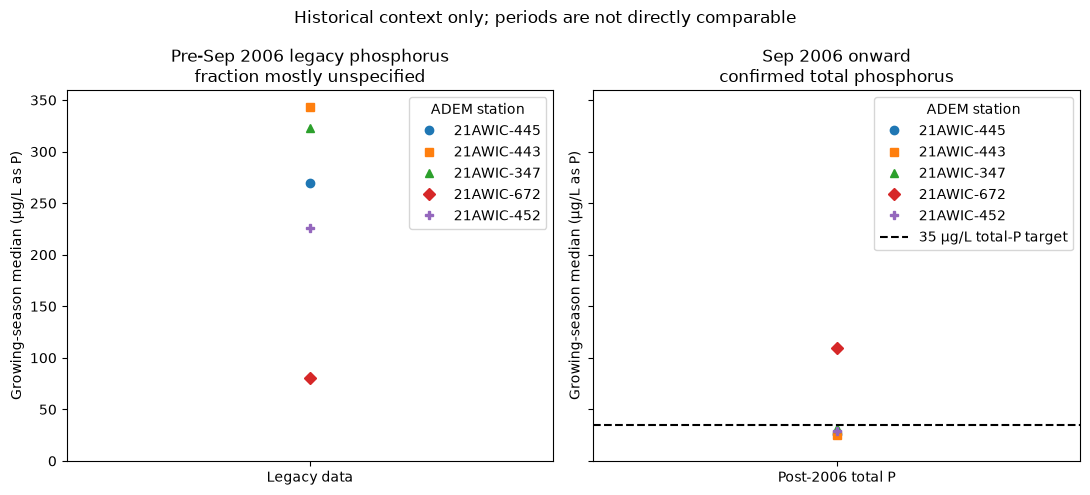

In [13]:
import matplotlib.pyplot as plt

station_markers = {
    "21AWIC-445": "o",
    "21AWIC-443": "s",
    "21AWIC-347": "^",
    "21AWIC-672": "D",
    "21AWIC-452": "P",
}
station_colors = {
    station: f"C{index}"
    for index, station in enumerate(ADEM_STATION_IDS)
}

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(11, 5))

for station in ADEM_STATION_IDS:
    station_result = station_summary.loc[
        station_summary["MonitoringLocationIdentifier"].eq(station)
    ].iloc[0]
    axes[0].plot(
        [0],
        [station_result["legacy_detected_only_median_ug_p_l"]],
        marker=station_markers[station],
        color=station_colors[station],
        linestyle="None",
        label=station,
    )
    axes[1].plot(
        [0],
        [station_result["post_2006_total_median_ug_p_l"]],
        marker=station_markers[station],
        color=station_colors[station],
        linestyle="None",
        label=station,
    )

axes[0].set_title("Pre-Sep 2006 legacy phosphorus\nfraction mostly unspecified")
axes[1].set_title("Sep 2006 onward\nconfirmed total phosphorus")
axes[0].set_ylabel("Growing-season median (µg/L as P)")
axes[0].set_xticks([0], ["Legacy data"])
axes[1].set_xticks([0], ["Post-2006 total P"])
axes[0].set_xlim(-0.4, 0.4)
axes[1].set_xlim(-0.4, 0.4)
axes[1].set_ylabel("Growing-season median (µg/L as P)")
axes[1].axhline(
    y=35,
    color="black",
    linestyle="--",
    label="35 µg/L total-P target",
)
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.legend(title="ADEM station")
fig.suptitle("Historical context only; periods are not directly comparable")
fig.tight_layout()
plt.show()

The figure keeps the two periods separate and uses the same concentration units for context. The pre-2006 values are retained as legacy phosphorus, but the missing fraction metadata and nondetect sensitivity assumptions mean they cannot establish a directly comparable change in total phosphorus. For the post-2006 period, compare the station medians and sample counts with the 35 µg/L target; verify any surprising values against the raw records, units, and station sampling history.

## 2.4. Check the post-2006 station above the target

This cell checks station 21AWIC-672, whose post-2006 total-phosphorus median exceeded 35 µg/L. It reports how many station-date medians are above the target and displays the underlying records, including dates, units, sample fraction, detection limits, and method information. High values are flagged for review, not automatically removed.

In [14]:
station_to_check = "21AWIC-672"

station_day_check = post_2006_station_dates.loc[
    post_2006_station_dates["MonitoringLocationIdentifier"].eq(station_to_check)
].copy()

station_day_check["station_date_median_ug_p_l"] = (
    station_day_check["detected_median_mg_p_l"] * 1000
)

detected_station_days = station_day_check[
    "detected_median_mg_p_l"
].dropna()

print(f"Station: {station_to_check}")
print(f"Station-dates with detected results: {len(detected_station_days)}")
print(
    "Station-date medians above 35 µg/L:",
    int((detected_station_days > LIMIT_MG_P_L).sum()),
)
print(
    "Percent of detected station-dates above 35 µg/L:",
    f"{(detected_station_days > LIMIT_MG_P_L).mean() * 100:.1f}%",
)
print(
    "Median of station-date medians (µg/L as P):",
    f"{detected_station_days.median() * 1000:.1f}",
)

station_day_check.sort_values(
    "station_date_median_ug_p_l",
    ascending=False,
)

Station: 21AWIC-672
Station-dates with detected results: 76
Station-date medians above 35 µg/L: 76
Percent of detected station-dates above 35 µg/L: 100.0%
Median of station-date medians (µg/L as P): 110.0


,MonitoringLocationIdentifier,ActivityStartDate,detected_median_mg_p_l,detected_sample_count,nondetected_sample_count,station_date_median_ug_p_l
412,21AWIC-672,2019-10-01,0.274,1,0,274.0
384,21AWIC-672,2015-10-07,0.247,1,0,247.0
360,21AWIC-672,2012-07-11,0.201,1,0,201.0
408,21AWIC-672,2019-06-06,0.201,1,0,201.0
404,21AWIC-672,2018-09-05,0.187,1,0,187.0
...,...,...,...,...,...,...
385,21AWIC-672,2016-04-06,0.048,1,0,48.0
395,21AWIC-672,2017-07-05,0.045,1,0,45.0
371,21AWIC-672,2014-04-02,0.044,1,0,44.0
425,21AWIC-672,2021-10-07,0.039,1,0,39.0


## Screen station-date medians for potential outliers

This cell uses the 1.5×IQR rule to flag unusually low or high detected station-date medians for station 21AWIC-672. The output lists flagged dates and plots all detected daily medians; flagged values require review against the raw results and metadata and are not automatically excluded.

In [15]:
outlier_data = station_day_check.dropna(
    subset=["station_date_median_ug_p_l"]
).copy()

q1 = outlier_data["station_date_median_ug_p_l"].quantile(0.25)
q3 = outlier_data["station_date_median_ug_p_l"].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - OUTLIER_IQR_MULTIPLIER * iqr
upper_fence = q3 + OUTLIER_IQR_MULTIPLIER * iqr

outlier_data["potential_outlier"] = (
    (outlier_data["station_date_median_ug_p_l"] < lower_fence)
    | (outlier_data["station_date_median_ug_p_l"] > upper_fence)
)

print(f"Station: {station_to_check}")
print(f"Q1: {q1:.1f} µg/L as P")
print(f"Q3: {q3:.1f} µg/L as P")
print(f"IQR: {iqr:.1f} µg/L as P")
print(f"Lower fence: {lower_fence:.1f} µg/L as P")
print(f"Upper fence: {upper_fence:.1f} µg/L as P")
print(f"Potential outlier station-dates: {outlier_data['potential_outlier'].sum()}")

potential_outliers = outlier_data.loc[
    outlier_data["potential_outlier"]
].sort_values(
    "station_date_median_ug_p_l",
    ascending=False,
)

potential_outliers[
    [
        "MonitoringLocationIdentifier",
        "ActivityStartDate",
        "station_date_median_ug_p_l",
        "detected_sample_count",
        "nondetected_sample_count",
    ]
]

Station: 21AWIC-672
Q1: 82.0 µg/L as P
Q3: 141.0 µg/L as P
IQR: 59.0 µg/L as P
Lower fence: -6.5 µg/L as P
Upper fence: 229.5 µg/L as P
Potential outlier station-dates: 2


,MonitoringLocationIdentifier,ActivityStartDate,station_date_median_ug_p_l,detected_sample_count,nondetected_sample_count
412,21AWIC-672,2019-10-01,274.0,1,0
384,21AWIC-672,2015-10-07,247.0,1,0


## Inspect flagged station-date records in the source data

This cell displays the original records for the flagged dates at station 21AWIC-672. The reported values are shown with their original units and sample metadata so the high measurements can be checked without altering the source data.

In [16]:
dates_to_check = ["2015-10-07", "2019-10-01"]

raw_station_check = data.loc[
    data["MonitoringLocationIdentifier"].eq("21AWIC-672")
    & data["ActivityStartDate"].isin(dates_to_check)
].copy()

raw_columns = [
    "ActivityStartDate",
    "ActivityStartTime/Time",
    "MonitoringLocationIdentifier",
    "ActivityIdentifier",
    "CharacteristicName",
    "ResultMeasureValue",
    "ResultMeasure/MeasureUnitCode",
    "ResultSampleFractionText",
    "ResultDetectionConditionText",
    "MeasureQualifierCode",
    "ResultStatusIdentifier",
    "ResultAnalyticalMethod/MethodName",
    "ResultAnalyticalMethod/MethodIdentifier",
    "LaboratoryName",
    "DetectionQuantitationLimitMeasure/MeasureValue",
    "DetectionQuantitationLimitMeasure/MeasureUnitCode",
    "ResultCommentText",
]

raw_station_check[raw_columns].sort_values(
    ["ActivityStartDate", "ActivityIdentifier"]
)

,ActivityStartDate,ActivityStartTime/Time,MonitoringLocationIdentifier,ActivityIdentifier,CharacteristicName,ResultMeasureValue,ResultMeasure/MeasureUnitCode,ResultSampleFractionText,ResultDetectionConditionText,MeasureQualifierCode,ResultStatusIdentifier,ResultAnalyticalMethod/MethodName,ResultAnalyticalMethod/MethodIdentifier,LaboratoryName,DetectionQuantitationLimitMeasure/MeasureValue,DetectionQuantitationLimitMeasure/MeasureUnitCode,ResultCommentText
3415,2015-10-07,12:30:00,21AWIC-672,21AWIC-230681_127357_173,Phosphorus,.247,mg/L,Total,NaN,NaN,Final,Phosphorus by Colorimetry,365.1,ADEM - BIRMINGHAM LAB,NaN,NaN,NaN
4101,2019-10-01,12:10:00,21AWIC-672,21AWIC-287180_152657_173,Phosphorus,.274,mg/L,Total,NaN,NaN,Final,Phosphorus by Colorimetry,365.1,ADEM - BIRMINGHAM LAB,NaN,NaN,NaN


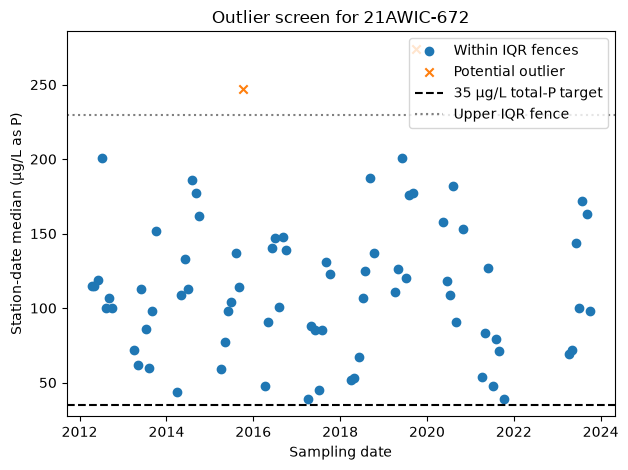

In [17]:
fig, ax = plt.subplots()

regular_dates = outlier_data.loc[~outlier_data["potential_outlier"]]
flagged_dates = outlier_data.loc[outlier_data["potential_outlier"]]

ax.scatter(
    pd.to_datetime(regular_dates["ActivityStartDate"]),
    regular_dates["station_date_median_ug_p_l"],
    marker="o",
    label="Within IQR fences",
)
ax.scatter(
    pd.to_datetime(flagged_dates["ActivityStartDate"]),
    flagged_dates["station_date_median_ug_p_l"],
    marker="x",
    label="Potential outlier",
)
ax.axhline(
    y=35,
    color="black",
    linestyle="--",
    label="35 µg/L total-P target",
)
ax.axhline(
    y=upper_fence,
    color="gray",
    linestyle=":",
    label="Upper IQR fence",
)

ax.set_xlabel("Sampling date")
ax.set_ylabel("Station-date median (µg/L as P)")
ax.set_title(f"Outlier screen for {station_to_check}")
ax.legend()
fig.tight_layout()
plt.show()

In [18]:
station_record_check = post_2006_total_data.loc[
    post_2006_total_data["MonitoringLocationIdentifier"].eq(station_to_check)
].copy()

station_record_check["phosphorus_ug_p_l"] = (
    station_record_check["phosphorus_mg_p_l"] * 1000
)

audit_columns = [
    "ActivityStartDate",
    "ActivityIdentifier",
    "ResultMeasureValue",
    "ResultMeasure/MeasureUnitCode",
    "phosphorus_ug_p_l",
    "CharacteristicName",
    "ResultSampleFractionText",
    "ResultDetectionConditionText",
    "DetectionQuantitationLimitMeasure/MeasureValue",
    "DetectionQuantitationLimitMeasure/MeasureUnitCode",
    "MeasureQualifierCode",
    "ResultAnalyticalMethod/MethodName",
    "ResultCommentText",
]

station_record_check[audit_columns].sort_values(
    "phosphorus_ug_p_l",
    ascending=False,
    na_position="last",
)

,ActivityStartDate,ActivityIdentifier,ResultMeasureValue,ResultMeasure/MeasureUnitCode,phosphorus_ug_p_l,CharacteristicName,ResultSampleFractionText,ResultDetectionConditionText,DetectionQuantitationLimitMeasure/MeasureValue,DetectionQuantitationLimitMeasure/MeasureUnitCode,MeasureQualifierCode,ResultAnalyticalMethod/MethodName,ResultCommentText
4101,2019-10-01,21AWIC-287180_152657_173,.274,mg/L,274.0,Phosphorus,Total,NaN,NaN,NaN,NaN,Phosphorus by Colorimetry,NaN
3415,2015-10-07,21AWIC-230681_127357_173,.247,mg/L,247.0,Phosphorus,Total,NaN,NaN,NaN,NaN,Phosphorus by Colorimetry,NaN
4000,2019-06-06,21AWIC-279847_148684_173,.201,mg/L,201.0,Phosphorus,Total,NaN,NaN,NaN,NaN,Phosphorus by Colorimetry,NaN
3122,2012-07-11,21AWIC-181106_91717_173,.201,mg/L,201.0,Phosphorus,Total,NaN,0.0090,mg/L,NaN,Phosphorus by Colorimetry,NaN
3808,2018-09-05,21AWIC-273883_145920_173,.187,mg/L,187.0,Phosphorus,Total,NaN,NaN,NaN,NaN,Phosphorus by Colorimetry,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3684,2016-04-06,21AWIC-234911_129772_173,.048,mg/L,48.0,Phosphorus,Total,NaN,NaN,NaN,NaN,Phosphorus by Colorimetry,NaN
3790,2017-07-05,21AWIC-258403_139709_173,.045,mg/L,45.0,Phosphorus,Total,NaN,NaN,NaN,NaN,Phosphorus by Colorimetry,NaN
3330,2014-04-02,21AWIC-208464_117479_173,.044,mg/L,44.0,Phosphorus,Total,NaN,NaN,NaN,NaN,Phosphorus by Colorimetry,NaN
4415,2021-10-07,21AWIC-309123_163214_173,.039,mg/L,39.0,Phosphorus,Total,NaN,0.0070,mg/L,NaN,Phosphorus by Colorimetry,NaN


## 3.1. Software versions

This final cell records the Python and package versions used for the analysis so the computational environment is documented.

In [19]:
import sys
import matplotlib
import numpy as np
import pandas as pd

print(f"Python: {sys.version.split()[0]}")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")

Python: 3.14.7
pandas: 3.0.6
NumPy: 2.5.3
Matplotlib: 3.11.2
